На линкот е дадено податочно множество со дијагнози и третмани за ментално здравје заедно со нивниот исход.

- Најнапред, направете Exploratory Data Analysis (EDA) врз податочното множество.
- Потоа, соодветно претпроцесирајте ги податоците.
- На крај, тренирајте и евалуирајте модел по избор за предвидување на исходот врз основа на карактеристиките за дијагноза и третман.

Dataset shape: (500, 17)

First few rows:
   Patient ID   Age  Gender                  Diagnosis  \
0           1  43.0  Female  Major Depressive Disorder   
1           2  40.0  Female  Major Depressive Disorder   
2           3  55.0  Female  Major Depressive Disorder   
3           4  34.0  Female  Major Depressive Disorder   
4           5  52.0    Male             Panic Disorder   

   Symptom Severity (1-10)  Mood Score (1-10)  Sleep Quality (1-10)  \
0                       10                  5                     8   
1                        9                  5                     4   
2                        6                  3                     4   
3                        6                  3                     6   
4                        7                  6                     6   

   Physical Activity (hrs/week)        Medication               Therapy Type  \
0                           NaN  Mood Stabilizers      Interpersonal Therapy   
1                     

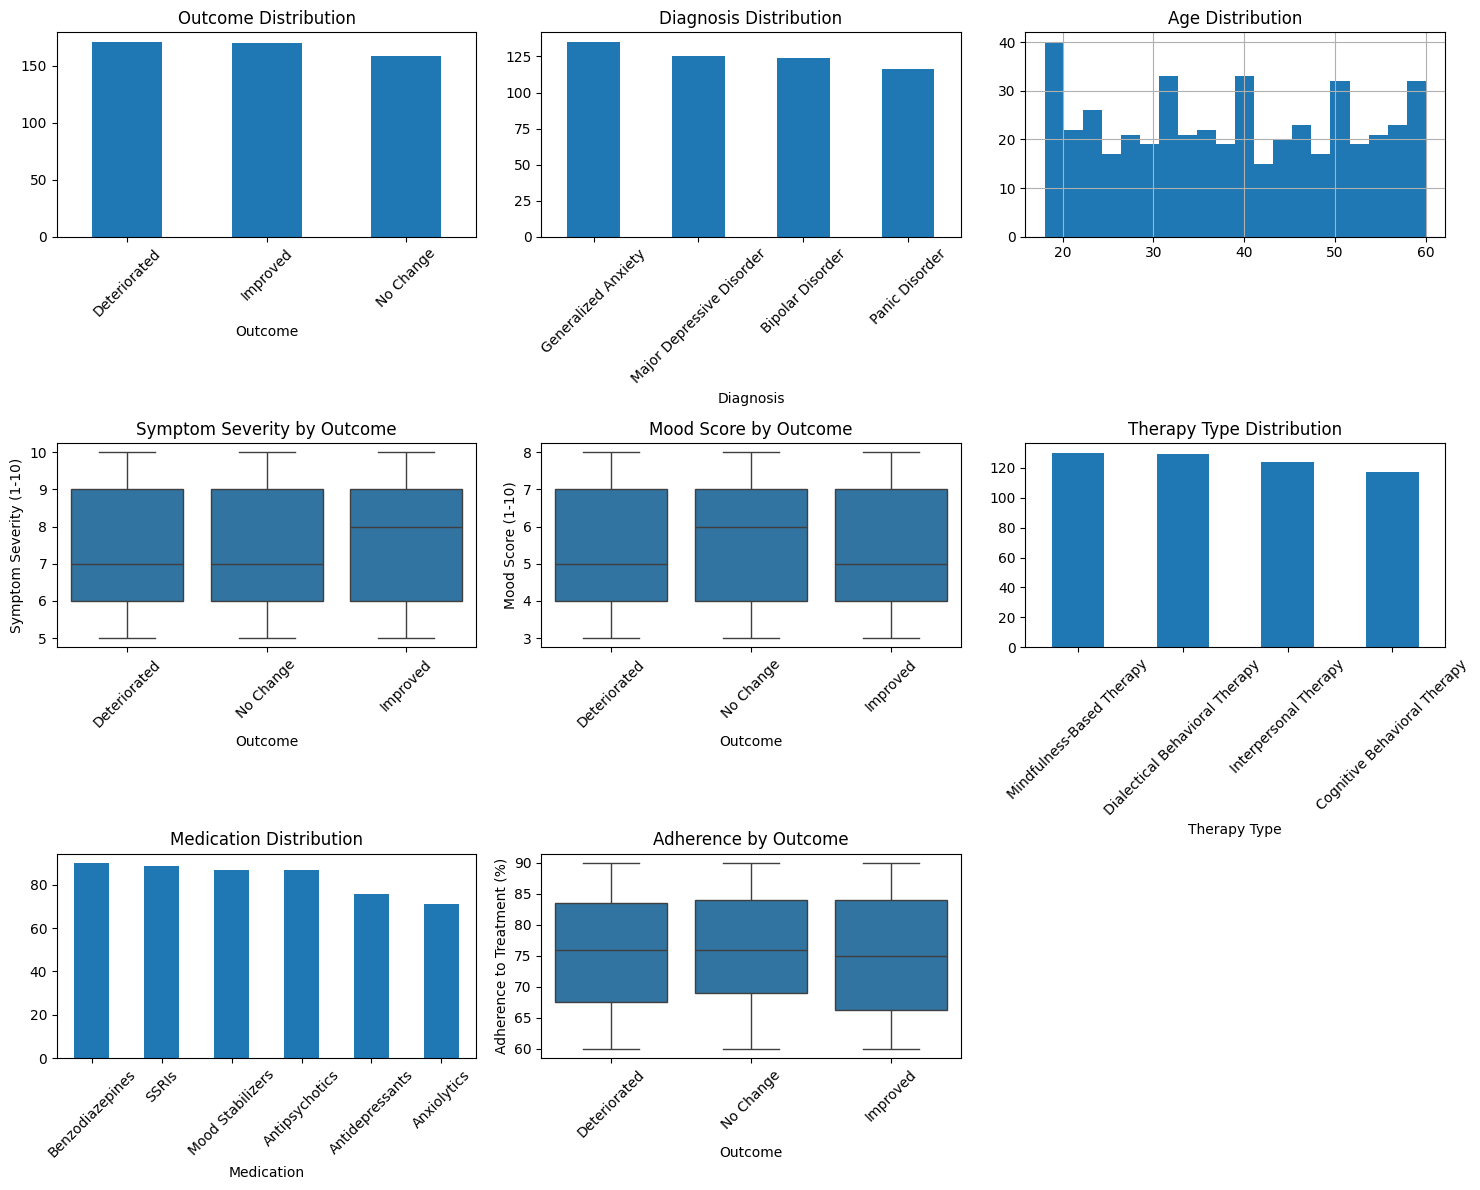

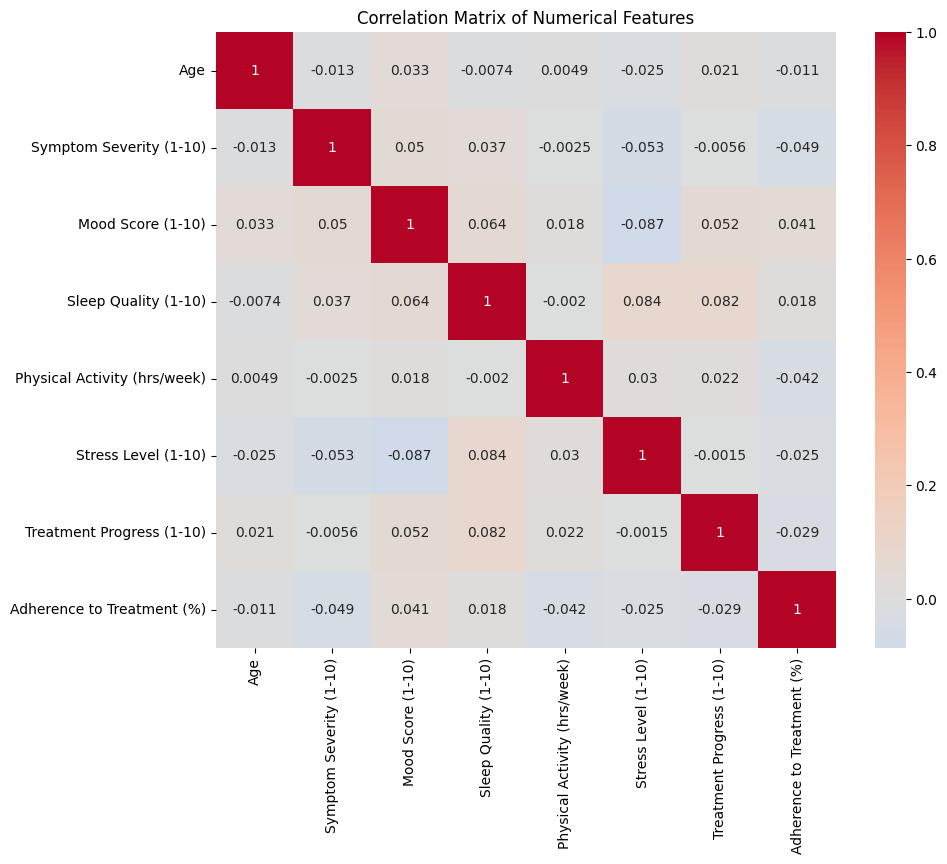

In [47]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Load data
df = pd.read_csv('mental_health_diagnosis_treatment_data.csv')

# Basic info
print("Dataset shape:", df.shape)
print("\nFirst few rows:")
print(df.head())

print("\nData types and missing values:")
print(df.info())

print("\nMissing values per column:")
print(df.isnull().sum())

print("\nBasic statistics:")
print(df.describe())

# Check target variable distribution
print("\nOutcome distribution:")
print(df['Outcome'].value_counts())

# Visualizations
plt.figure(figsize=(15, 12))

# Outcome distribution
plt.subplot(3, 3, 1)
df['Outcome'].value_counts().plot(kind='bar')
plt.title('Outcome Distribution')
plt.xticks(rotation=45)

# Diagnosis distribution
plt.subplot(3, 3, 2)
df['Diagnosis'].value_counts().plot(kind='bar')
plt.title('Diagnosis Distribution')
plt.xticks(rotation=45)

# Age distribution
plt.subplot(3, 3, 3)
df['Age'].hist(bins=20)
plt.title('Age Distribution')

# Symptom severity by outcome
plt.subplot(3, 3, 4)
sns.boxplot(data=df, x='Outcome', y='Symptom Severity (1-10)')
plt.title('Symptom Severity by Outcome')
plt.xticks(rotation=45)

# Mood score by outcome
plt.subplot(3, 3, 5)
sns.boxplot(data=df, x='Outcome', y='Mood Score (1-10)')
plt.title('Mood Score by Outcome')
plt.xticks(rotation=45)

# Therapy type distribution
plt.subplot(3, 3, 6)
df['Therapy Type'].value_counts().plot(kind='bar')
plt.title('Therapy Type Distribution')
plt.xticks(rotation=45)

# Medication distribution
plt.subplot(3, 3, 7)
df['Medication'].value_counts().plot(kind='bar')
plt.title('Medication Distribution')
plt.xticks(rotation=45)

# Adherence by outcome
plt.subplot(3, 3, 8)
sns.boxplot(data=df, x='Outcome', y='Adherence to Treatment (%)')
plt.title('Adherence by Outcome')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# Correlation analysis for numerical features
numerical_cols = ['Age', 'Symptom Severity (1-10)', 'Mood Score (1-10)', 
                 'Sleep Quality (1-10)', 'Physical Activity (hrs/week)', 
                 'Stress Level (1-10)', 'Treatment Progress (1-10)', 
                 'Adherence to Treatment (%)']

plt.figure(figsize=(10, 8))
correlation_matrix = df[numerical_cols].corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0)
plt.title('Correlation Matrix of Numerical Features')
plt.show()

In [48]:
# Handle missing values
# Fill numerical columns with median
numerical_columns = ['Age', 'Physical Activity (hrs/week)', 'Stress Level (1-10)']
for col in numerical_columns:
    df[col].fillna(df[col].median(), inplace=True)

# Fill categorical columns with mode
categorical_columns = ['Gender']
for col in categorical_columns:
    df[col].fillna(df[col].mode()[0], inplace=True)

# Encode categorical variables
label_encoders = {}
categorical_features = ['Gender', 'Diagnosis', 'Medication', 'Therapy Type', 'AI-Detected Emotional State']

for feature in categorical_features:
    le = LabelEncoder()
    df[feature] = le.fit_transform(df[feature].astype(str))
    label_encoders[feature] = le

# Encode target variable
target_encoder = LabelEncoder()
df['Outcome_encoded'] = target_encoder.fit_transform(df['Outcome'])

# Select features for modeling
feature_columns = ['Age', 'Gender', 'Diagnosis', 'Symptom Severity (1-10)', 
                  'Mood Score (1-10)', 'Sleep Quality (1-10)', 
                  'Physical Activity (hrs/week)', 'Medication', 'Therapy Type',
                  'Treatment Duration (weeks)', 'Stress Level (1-10)', 
                  'Treatment Progress (1-10)', 'AI-Detected Emotional State',
                  'Adherence to Treatment (%)']

X = df[feature_columns]
y = df['Outcome_encoded']

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, 
                                                    random_state=42, 
                                                    stratify=y)

# Scale numerical features
scaler = StandardScaler()
numerical_cols_to_scale = ['Age', 'Symptom Severity (1-10)', 'Mood Score (1-10)',
                          'Sleep Quality (1-10)', 'Physical Activity (hrs/week)',
                          'Treatment Duration (weeks)', 'Stress Level (1-10)',
                          'Treatment Progress (1-10)', 'Adherence to Treatment (%)']

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[numerical_cols_to_scale] = scaler.fit_transform(X_train[numerical_cols_to_scale])
X_test_scaled[numerical_cols_to_scale] = scaler.transform(X_test[numerical_cols_to_scale])

Random Forest Model Evaluation
Accuracy: 0.4100

Classification Report:
              precision    recall  f1-score   support

Deteriorated       0.35      0.53      0.42        34
    Improved       0.53      0.47      0.50        34
   No Change       0.37      0.22      0.27        32

    accuracy                           0.41       100
   macro avg       0.42      0.41      0.40       100
weighted avg       0.42      0.41      0.40       100



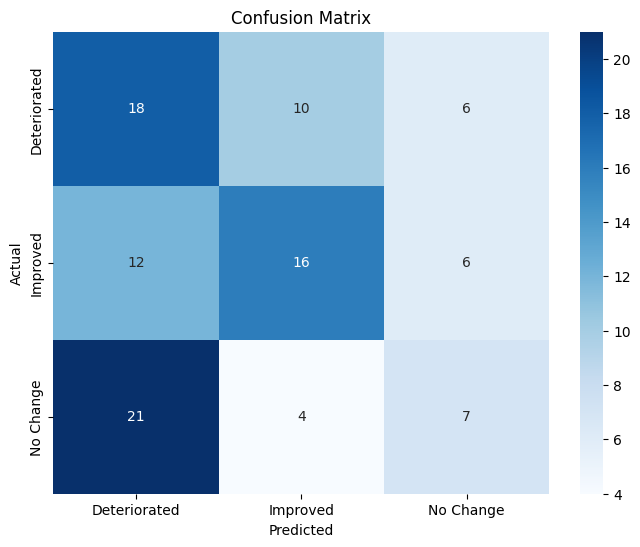

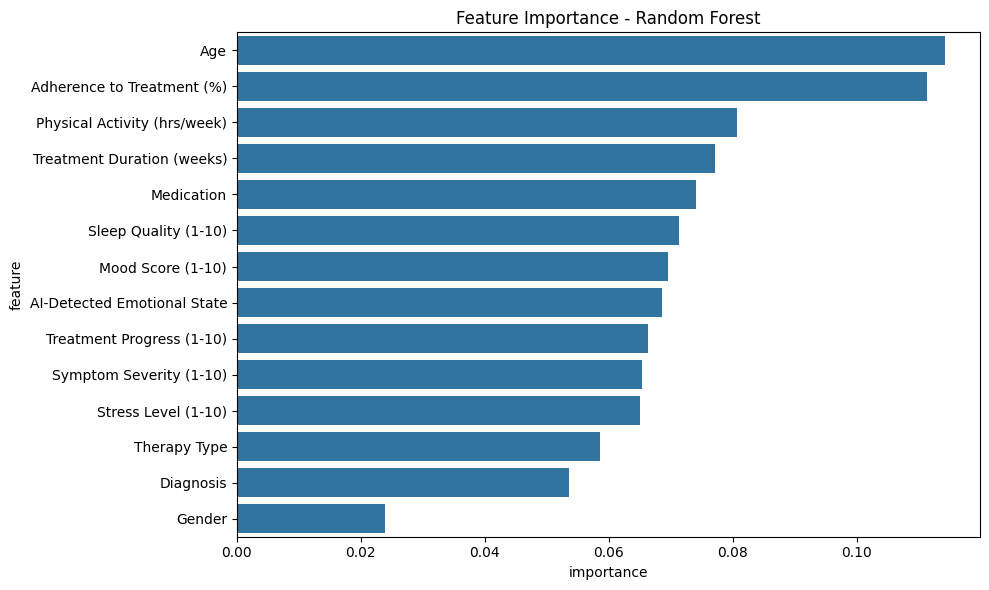


Top 10 Most Important Features:
                         feature  importance
0                            Age    0.114217
13    Adherence to Treatment (%)    0.111301
6   Physical Activity (hrs/week)    0.080652
9     Treatment Duration (weeks)    0.077206
7                     Medication    0.074129
5           Sleep Quality (1-10)    0.071392
4              Mood Score (1-10)    0.069557
12   AI-Detected Emotional State    0.068621
11     Treatment Progress (1-10)    0.066328
3        Symptom Severity (1-10)    0.065436


In [49]:
# Train Random Forest model
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train_scaled, y_train)

# Make predictions
y_pred = rf_model.predict(X_test_scaled)
y_pred_proba = rf_model.predict_proba(X_test_scaled)

# Evaluate model
print("Random Forest Model Evaluation")
print("=" * 50)
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, 
                          target_names=target_encoder.classes_))

# Confusion Matrix
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=target_encoder.classes_,
            yticklabels=target_encoder.classes_)
plt.title('Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

# Feature Importance
feature_importance = pd.DataFrame({
    'feature': feature_columns,
    'importance': rf_model.feature_importances_
}).sort_values('importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=feature_importance, x='importance', y='feature')
plt.title('Feature Importance - Random Forest')
plt.tight_layout()
plt.show()

print("\nTop 10 Most Important Features:")
print(feature_importance.head(10))